# <center> Predicting Zebrafish Movements in Virtual Reality

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from IPython.display import display
import functions
from tqdm import tqdm
from matplotlib import animation
from IPython.display import Image
import pickle


## Context

This project is part of a collaboration between EPFL and UNIL.
It aims to understand the perceptual and computational rules underlying social interactions in zebrafish through behavioral and neural data analysis.

In this experiment, a single zebrafish swims in a controlled environment equipped with a virtual reality system.  
One or several visual stimuli (dots) are projected on a screen, simulating the motion patterns of another fish, typically a sequence of “bursts and glides” characteristic of zebrafish swimming behavior.  
The fish’s trajectory, orientation, and velocity are continuously tracked, as well as the trajectories and properties of the stimuli.

## Objective :

The goal is to compare two types of data representation and to select one of them to continue further preprocessing. 

> ABSOLUTE : coordinates of stimuli + flag (0 or 1 if the stimuli is active)

> PIXEL POLAR EGOCENTRIC ENCODING : Creates a matrix, each element represent a specific location. If this location contains 1 or more stimuli, the value of the element is 1 else 0.

In this notebook we will use the first data representation. For the second one look at PXL_POLAR.ipynb

 To decide which one is better, we will run an XGBoost using the two representations and compare the RMSE. In order to be 'fair' between the two representation, we do approximately the same preprocessing and feature engineering for them.

In [2]:
# We download the dict extracted from the pipeline
with open("abs_dict.pkl", "rb") as f:
    abs_dict = pickle.load(f)

#We create a big dataset with all fish
df_abs = functions.stack_dict_pipeline(abs_dict)
    

In [3]:
#keep only 50000 first rows for faster processing
#df_abs = df_abs.iloc[:50000, :]

## <center> Exploring dataset and preprocessing

In [4]:
print("Absolute dataframe shape : " + str(df_abs.shape))

Absolute dataframe shape : (4702500, 31)


In [5]:
df_abs.head()

,frame,source_frame,stimulus,f_x,f_y,f_ori,d0_x,d0_y,d0_stim,d1_x,...,d5_x,d5_y,d5_stim,d6_x,d6_y,d6_stim,d7_x,d7_y,d7_stim,fish_id
0,0,0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,inter_stim_pause,NaN,...,NaN,NaN,none,NaN,NaN,none,NaN,NaN,none,0
1,1,1,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,inter_stim_pause,NaN,...,NaN,NaN,none,NaN,NaN,none,NaN,NaN,none,0
2,2,2,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,inter_stim_pause,NaN,...,NaN,NaN,none,NaN,NaN,none,NaN,NaN,none,0
3,3,3,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,inter_stim_pause,NaN,...,NaN,NaN,none,NaN,NaN,none,NaN,NaN,none,0
4,4,4,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,inter_stim_pause,NaN,...,NaN,NaN,none,NaN,NaN,none,NaN,NaN,none,0


##### There is a non sens to give conditional experiment information to the model. We want to give the present and past full state position of the fish and its visual field.

In [6]:
df_abs = df_abs.drop(columns=['stimulus'])

# transform dk_stim for each stimulus k into 0 if the feature is 'none' else 1
for k in range(8):
    df_abs[f'd{k}_stim'] = df_abs[f'd{k}_stim'].apply(lambda x: 0 if x == 'none' else 1)
df_abs = df_abs.drop(columns=['fish_id']) # Make no sens to keep fish_id for prediction
df_abs = df_abs.drop(columns=['frame']) # Make no sens to keep frame for prediction

In [7]:
print("------------ Absolute dataframe ------------")
df_abs, _ = functions.remove_nan_plus_constant_and_correlated_features(df_abs, corr_threshold=1.0)

------------ Absolute dataframe ------------
The dataset contains : 0.4784688995215311% of NaN.
There are few NaN, therefore we make the choice to remove them.
✅ No highly correlated features found.


In [8]:
df_abs = functions.compute_d_orientation(df_abs)
df_abs = functions.compute_speed(df_abs)

#df_abs = df_abs.drop(columns=['f_x', 'f_y', 'f_ori'])

df_abs.head()

Removed rows with |d_ori| > 1 radians. There are artefacts representing less than 4% of the data.


,f_speed,d_ori,source_frame,f_x,f_y,f_ori,d0_x,d0_y,d0_stim,d1_x,...,d4_stim,d5_x,d5_y,d5_stim,d6_x,d6_y,d6_stim,d7_x,d7_y,d7_stim
1502,0.0,-0.012,1502,167.0,226.0,3.105185,171.323132,155.772777,1,169.566389,...,0,166.0,226.0,0,166.0,226.0,0,166.0,226.0,0
1503,0.0,-0.024,1503,167.0,226.0,3.081185,171.323132,155.772777,1,169.566389,...,0,166.0,226.0,0,166.0,226.0,0,166.0,226.0,0
1504,0.0,0.027,1504,167.0,226.0,3.108185,171.323132,155.772777,1,169.566389,...,0,166.0,226.0,0,166.0,226.0,0,166.0,226.0,0
1505,0.0,0.000,1505,167.0,226.0,3.108185,171.323132,155.772777,1,169.566389,...,0,166.0,226.0,0,166.0,226.0,0,166.0,226.0,0
1506,0.0,-0.056,1506,167.0,226.0,3.052185,171.323132,155.772777,1,169.566389,...,0,166.0,226.0,0,166.0,226.0,0,166.0,226.0,0


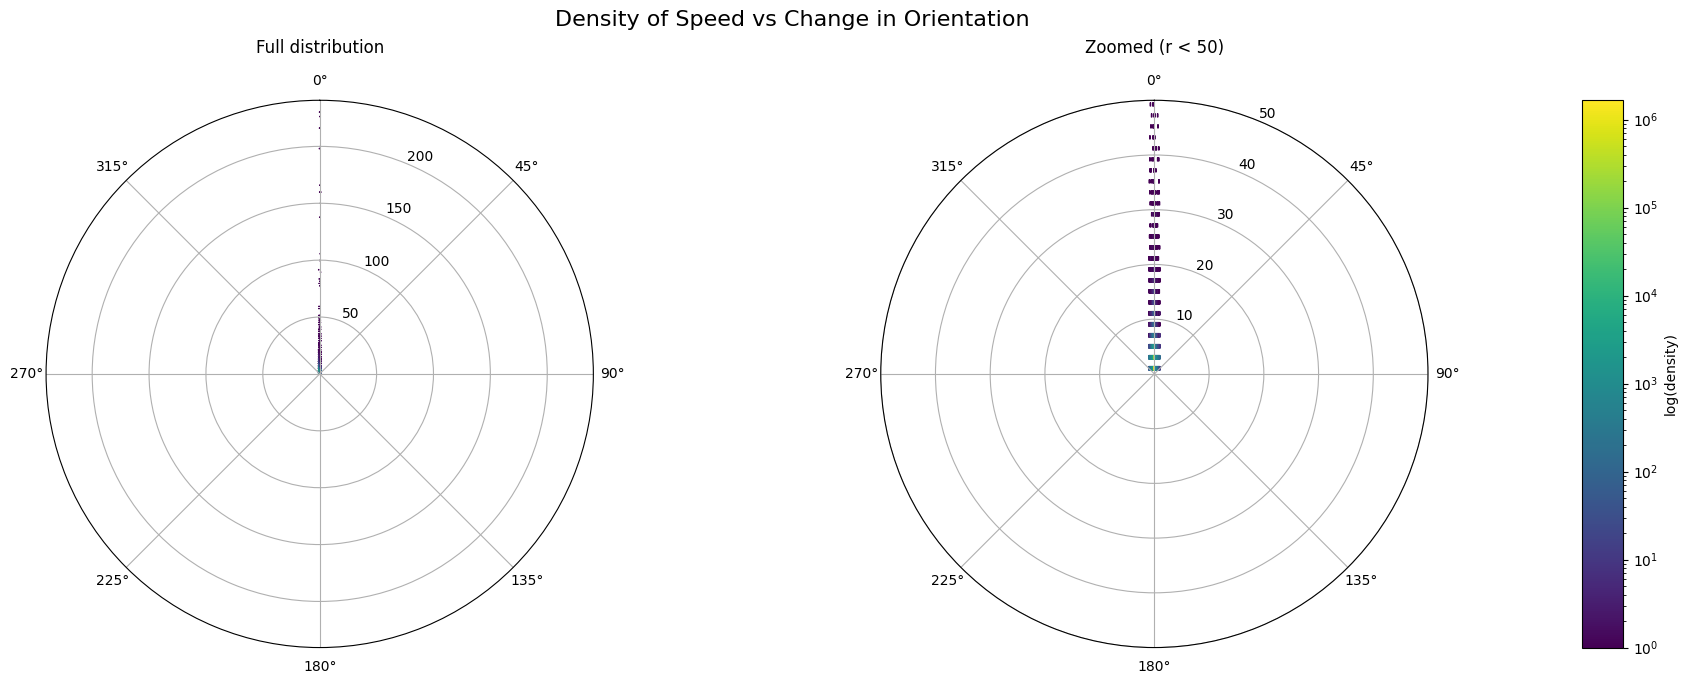

In [10]:
# Convert to polar coordinates (r = speed, θ = change in orientation)
r = df_abs["f_speed"]
theta = df_abs["d_ori"]

# --- Create figure layout ---
fig = plt.figure(figsize=(18, 7))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.05])  # full plot | zoomed plot | colorbar

# Shared normalization (so both plots use same color range)
vmin, vmax = 1, 1000
norm = plt.Normalize(vmin=vmin, vmax=vmax)

# --- 📊 (1) Full plot (identical to your original one) ---
ax1 = fig.add_subplot(gs[0, 0], polar=True)
ax1.set_theta_zero_location("N")
ax1.set_theta_direction(-1)
hb1 = ax1.hexbin(theta, r, gridsize=100, cmap="viridis", bins='log')
ax1.set_title("Full distribution", pad=15)

# --- 🔍 (2) Zoomed plot ---
ax2 = fig.add_subplot(gs[0, 1], polar=True)
ax2.set_theta_zero_location("N")
ax2.set_theta_direction(-1)
hb2 = ax2.hexbin(theta, r, gridsize=100, cmap="viridis", bins='log')
ax2.set_rmax(50)  # zoom on low speeds
ax2.set_title("Zoomed (r < 50)", pad=15)

# --- 🎨 (3) Separate colorbar ---
cax = fig.add_subplot(gs[0, 2])
cb = fig.colorbar(hb1, cax=cax)
cb.set_label("log(density)")

plt.suptitle("Density of Speed vs Change in Orientation", fontsize=16, y=0.97)
plt.tight_layout()
plt.show()

### Interpreting the Polar Density Plot

This plot shows the **distribution of fish movements** in **polar coordinates**, where:

- **r (radius)** = the *speed* of the fish (the magnitude of its displacement between frames).  
- **θ (angle)** = the *change in orientation* (Δorientation, in radians) between consecutive frames.

Each hexagonal bin represents how frequently a given combination of speed and turning angle occurs:
- Points near **θ = 0** correspond to **straight motion** (no turning).  
- Points near **|θ| = π/2** or **π** correspond to **sharp turns or reversals**.  
- The **color intensity** encodes how often those motions occur (darker = more frequent).

As the points near θ = 0, we will simply use orientation in radian rather making more trigonometric computations.

_

In [11]:
df_abs = functions.make_egocentric(df_abs)

In [12]:
df_abs_feature_engineered = functions.add_engineered_features(df_abs, representation="absolute", n_stimuli=8)

In [13]:
df, created_lag_cols = functions.add_lag_features_for_all(df_abs_feature_engineered, 0.5, subsample=5)

/Users/nayan/Desktop/Research/work with data/mp_semiCL_behavior/notebooks/functions.py:702: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[lag_col] = df[col].shift(lag)
/Users/nayan/Desktop/Research/work with data/mp_semiCL_behavior/notebooks/functions.py:702: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[lag_col] = df[col].shift(lag)
/Users/nayan/Desktop/Research/work with data/mp_semiCL_behavior/notebooks/functions.py:702: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.in

Created 195 lag features for 65 base columns, using lags from 5 to 15 frames (step=5, horizon ≈ 0.50 s at 30 fps).


/Users/nayan/Desktop/Research/work with data/mp_semiCL_behavior/notebooks/functions.py:702: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[lag_col] = df[col].shift(lag)
/Users/nayan/Desktop/Research/work with data/mp_semiCL_behavior/notebooks/functions.py:702: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[lag_col] = df[col].shift(lag)
/Users/nayan/Desktop/Research/work with data/mp_semiCL_behavior/notebooks/functions.py:702: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.in

In [14]:
delta_t = 5

df['f_speed_next'] = df['f_speed'].shift(-delta_t)
df['d_ori_next'] = df['d_ori'].shift(-delta_t)

# Drop only rows where future targets are missing
df = df.dropna(subset=["f_speed_next", "d_ori_next"])

df.head()

/var/folders/gx/054mtq011yv3wl3578m4k9x40000gn/T/ipykernel_64413/885744865.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['f_speed_next'] = df['f_speed'].shift(-delta_t)
/var/folders/gx/054mtq011yv3wl3578m4k9x40000gn/T/ipykernel_64413/885744865.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['d_ori_next'] = df['d_ori'].shift(-delta_t)


,f_speed,d_ori,source_frame,f_x,f_y,f_ori,d0_x,d0_y,d0_stim,d1_x,...,d_ori_abs_lag_10,d_ori_abs_lag_15,d_ori_rolling_mean_30_lag_5,d_ori_rolling_mean_30_lag_10,d_ori_rolling_mean_30_lag_15,d_ori_trend_30_lag_5,d_ori_trend_30_lag_10,d_ori_trend_30_lag_15,f_speed_next,d_ori_next
1502,0.0,-0.012,1502,167.0,226.0,3.105185,4.323132,-70.227223,1,2.566389,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,-0.004
1503,0.0,-0.024,1503,167.0,226.0,3.081185,4.323132,-70.227223,1,2.566389,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.005
1504,0.0,0.027,1504,167.0,226.0,3.108185,4.323132,-70.227223,1,2.566389,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.025
1505,0.0,0.000,1505,167.0,226.0,3.108185,4.323132,-70.227223,1,2.566389,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.048
1506,0.0,-0.056,1506,167.0,226.0,3.052185,4.323132,-70.227223,1,2.566389,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,-0.071


## <center> Creates train - val - test set

##### Our goal is to predict the fish’s next position and orientation $x_{t+1}$, $y_{t+1}$, and $\text{ori}_{t+1}$ using only the information available at the current time $t$.  
##### Formally, this means estimating the conditional expectations:

$$
\begin{aligned}
\hat{x}_{t+1} &= \mathbb{E}[x_{t+1} \mid \mathcal{F}_t] \\
\hat{y}_{t+1} &= \mathbb{E}[y_{t+1} \mid \mathcal{F}_t] \\
\hat{\text{ori}}_{t+1} &= \mathbb{E}[\text{ori}_{t+1} \mid \mathcal{F}_t]
\end{aligned}
$$

##### where $\mathcal{F}_t$ represents all information known at time $t$ (fish position, stimuli, condition, etc.).  
##### In other words, the model learns the most likely future state of the fish given the current context.

In [15]:
target_cols = ["f_speed_next", "d_ori_next"]

X_train, X_val, X_test, target_speed_train, target_speed_val, target_speed_test, target_ori_train, target_ori_val, target_ori_test = functions.temporal_train_val_test_split(df, target_cols)

✅ Temporal split complete:
  Train: 3147504 rows (70.0%)
  Val:   674465 rows (15.0%)
  Test:  674466 rows (15.0%)


##### Filtering the test set

Inter-stimulus pause frames (where all d*_stim flags are 0) contain no stimulus information. As our goal is to make a choici between 2 representations of visual input there is no sens to keep these rows in the test set.
The training set remains unfiltered, so the model still learns baseline fish dynamics.

In [16]:
# Identify all stimulus flag columns in X_test
stim_flag_cols = [col for col in X_test.columns 
                  if col.startswith("d") and col.endswith("_stim")]

# Create mask: True = at least one active stimulus in that row
active_stim_mask = (X_test[stim_flag_cols].sum(axis=1) > 0)

# Apply mask to X_test + targets
X_test_filtered = X_test[active_stim_mask].copy()
target_speed_test_filtered = target_speed_test[active_stim_mask].copy()
target_ori_test_filtered = target_ori_test[active_stim_mask].copy()

print(f"Original test size: {len(X_test)} rows")
print(f"Filtered test size: {len(X_test_filtered)} rows")
print(f"Removed {len(X_test) - len(X_test_filtered)} inter_stim_pause rows")

Original test size: 674466 rows
Filtered test size: 674466 rows
Removed 0 inter_stim_pause rows


## <center> Train XGBoost

In [17]:
cat_cols = X_train.select_dtypes(include=['object']).columns
cat_cols.tolist()

[]

In [18]:
# --- Train model for speed prediction ---
model_speed = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
model_speed.fit(X_train, target_speed_train, eval_set=[(X_val, target_speed_val)], verbose=False)


# --- Train model for Orientation prediction ---
model_ori = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
model_ori.fit(X_train, target_ori_train, eval_set=[(X_val, target_ori_val)], verbose=False)

# --- Predictions ---
pred_speed = model_speed.predict(X_test)
pred_ori = model_ori.predict(X_test)

# --- RMSE (Root Mean Squared Error) ---
rmse_speed = mean_squared_error(target_speed_test, pred_speed, squared=False)
rmse_ori = mean_squared_error(target_ori_test, pred_ori, squared=False)


# --- Display results ---
print("📊 Model Performance Summary:")
print(f"RMSE Speed: {rmse_speed:.4f}")
print(f"RMSE Orientation: {rmse_ori:.4f}")

📊 Model Performance Summary:
RMSE Speed: 0.9561
RMSE Orientation: 0.0719


/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [19]:
rmse_speed_norm = rmse_speed / (df['f_speed'].max() - df['f_speed'].min())
rmse_ori_norm = rmse_ori / (df['d_ori'].max() - df['d_ori'].min())

In [20]:
# --- Static baseline ---
# Hypothesis: fish does not move (same position and orientation)
baseline_pred_speed = df.loc[X_test.index, 'f_speed']
baseline_pred_ori = df.loc[X_test.index, 'd_ori']

baseline_rmse_speed = mean_squared_error(target_speed_test, baseline_pred_speed, squared=False) / (df['f_speed'].max() - df['f_speed'].min())
baseline_rmse_ori = mean_squared_error(target_ori_test, baseline_pred_ori, squared=False) / (df['d_ori'].max() - df['d_ori'].min())

/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [21]:
# Build summary table
results_df = pd.DataFrame({
    "Metric": ["Speed", "Change in Orientation (rad)"],
    "Model RMSE": [rmse_speed_norm, rmse_ori_norm],
    "Static Baseline RMSE": [baseline_rmse_speed, baseline_rmse_ori],
})

# Format for readability
results_df = results_df.round(4)

# Display nicely
print("📊 Model Performance Summary:\n")
display(
    results_df.style.set_table_styles([
        {"selector": "th", "props": [("font-weight", "bold"), ("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center")]}
    ])
    .set_caption("Comparison of Model and Baselines (normalized RMSE)")
)

📊 Model Performance Summary:



,Metric,Model RMSE,Static Baseline RMSE
0,Speed,0.004200,0.005600
1,Change in Orientation (rad),0.035900,0.050700
